# BigQuery ML Anomaly Detection

In [3]:
import os

PROJECT = !(gcloud config get-value core/project)
PROJECT = PROJECT[0]
BUCKET = PROJECT

os.environ["PROJECT"] = PROJECT
os.environ["BUCKET"] = BUCKET

In [17]:
#!pip install print-versions # works for python >= 3.8
!pip install google-cloud-bigquery[pandas]
#==2.34.3

  Using cached pyarrow-21.0.0-cp310-cp310-manylinux_2_28_x86_64.whl.metadata (3.3 kB)
Using cached pyarrow-21.0.0-cp310-cp310-manylinux_2_28_x86_64.whl (42.7 MB)
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 9.0.0
    Uninstalling pyarrow-9.0.0:
      Successfully uninstalled pyarrow-9.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
apache-beam 2.46.0 requires numpy<1.25.0,>=1.14.3, but you have numpy 2.2.6 which is incompatible.
apache-beam 2.46.0 requires pyarrow<10.0.0,>=3.0.0, but you have pyarrow 21.0.0 which is incompatible.
datasets 2.14.5 requires fsspec[http]<2023.9.0,>=2023.1.0, but you have fsspec 2025.7.0 which is incompatible.
bigframes 2.11.0 requires google-cloud-bigquery[bqstorage,pandas]>=3.31.0, but you have google-cloud-bigquery 3.21.0 which is incompatible.
bigframes 2.11.0 requires google-cloud-bigquery-storag

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
from google.cloud import bigquery
from IPython import get_ipython
from IPython.core.magic import register_cell_magic
from matplotlib import pyplot as plt

from print_versions import print_versions

import numpy as np
from pandas import DataFrame

print_versions(globals())

bq = bigquery.Client(project=PROJECT)

numpy==2.2.6
pandas==2.3.1
seaborn==0.13.2
google.cloud.bigquery==3.21.0


In [ ]:
# Allow you to easily have Python variables in SQL query.
@register_cell_magic("with_globals")
def with_globals(line, cell):
    contents = cell.format(**globals())
    if "print" in line:
        print(contents)
    get_ipython().run_cell(contents)

In [ ]:
!bq mk anomaly_demo

## ARIMA

-- This statement trains an ARIMA_PLUS model using BigQuery ML.
-- The model will be partitioned by 'symbol', creating a separate model for each stock.
-- Replace `your_dataset.your_table` with your actual BigQuery table name.

In [ ]:
%%bigquery --project {PROJECT}
SELECT *
FROM
  `bigquery-public-data`.new_york.citibike_trips
WHERE start_station_name LIKE '%Central Park%'
LIMIT 10;

In [ ]:
%%bigquery --project {PROJECT}
CREATE MODEL anomaly_demo.nyc_citibike_arima_model
OPTIONS
  (model_type = 'ARIMA_PLUS',
   time_series_timestamp_col = 'date',
   time_series_data_col = 'num_trips',
   time_series_id_col = 'start_station_name'
  ) AS
SELECT
   start_station_name,
   EXTRACT(DATE from starttime) AS date,
   COUNT(*) AS num_trips
FROM
  `bigquery-public-data`.new_york.citibike_trips
WHERE start_station_name LIKE '%Central Park%'
GROUP BY start_station_name, date


In [ ]:
%%bigquery --project {PROJECT}
SELECT
  *
FROM
ML.DETECT_ANOMALIES(
  MODEL anomaly_demo.nyc_citibike_arima_model,
  STRUCT(0.95 AS anomaly_prob_threshold)
)WHERE is_anomaly=True

In [ ]:
%%bigquery --project {PROJECT}
# New data:
SELECT
  *
FROM
ML.DETECT_ANOMALIES(
  MODEL anomaly_demo.nyc_citibike_arima_model,
  STRUCT(0.95 AS anomaly_prob_threshold),
  (SELECT
   start_station_name,
   EXTRACT(DATE from starttime) AS date,
   COUNT(*) AS num_trips
FROM
  `bigquery-public-data`.new_york.citibike_trips
  GROUP BY start_station_name, date
  )
)

## k-means

### Explore dataset:

In [ ]:
%%bigquery --project {PROJECT}
SELECT * EXCEPT(Time, Class)
FROM 
  `bigquery-public-data.ml_datasets.ulb_fraud_detection` LIMIT 10;

### Train k-means model

In [ ]:
%%bigquery --project {PROJECT}
CREATE MODEL anomaly_demo.kmeans_model
OPTIONS(
  model_type='kmeans',
  num_clusters= 8,
  kmeans_init_method = 'kmeans++'
)
AS
SELECT * EXCEPT(Time, Class)
FROM 
  `bigquery-public-data.ml_datasets.ulb_fraud_detection`;

## BQML Autoencoder 

### Training

In [ ]:
%%bigquery --project {PROJECT}
CREATE MODEL anomaly_demo.autoencoder_model2
OPTIONS(
  model_type='autoencoder',
  activation_fn='relu',
  batch_size=8,
  dropout=0.2,  
  hidden_units=[32, 16, 4, 16, 32],
  learn_rate=0.001,
  l1_reg_activation=0.0001,
  max_iterations=10,
  optimizer='adam'
)
AS
SELECT * EXCEPT(Time, Class)
FROM
  `bigquery-public-data.ml_datasets.ulb_fraud_detection`;

In [42]:
%%bigquery df --project {PROJECT}
SELECT
  *
FROM
ML.DETECT_ANOMALIES(
  MODEL anomaly_demo.autoencoder_model,
  STRUCT(0.005 AS contamination),
  TABLE `bigquery-public-data.ml_datasets.ulb_fraud_detection`
)
#WHERE is_anomaly=True
#LIMIT 100;

Query is running:   0%|          |

Downloading:   0%|          |

In [37]:
df

,is_anomaly,mean_squared_error,Time,V1,V2,V3,V4,V5,V6,V7,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,False,8.339335,282.0,-0.356466,0.725418,1.971749,0.831343,0.369681,-0.107776,0.751610,...,0.020804,0.424312,-0.015989,0.466754,-0.809962,0.657334,-0.043150,-0.046401,0.00,0
1,False,12.080049,14332.0,1.071950,0.340678,1.784068,2.846396,-0.751538,0.403028,-0.734920,...,-0.169632,-0.113604,0.067643,0.468669,0.223541,-0.112355,0.014015,0.021504,0.00,0
2,False,9.609766,32799.0,1.153477,-0.047859,1.358363,1.480620,-1.222598,-0.481690,-0.654461,...,0.125514,0.480049,-0.025964,0.701843,0.417245,-0.257691,0.060115,0.035332,0.00,0
3,False,8.383425,35799.0,-0.769798,0.622325,0.242491,-0.586652,0.527819,-0.104512,0.209909,...,0.152738,0.255654,-0.130237,-0.660934,-0.493374,0.331855,-0.011101,0.049089,0.00,0
4,False,11.507424,36419.0,1.047960,0.145048,1.624573,2.932652,-0.726574,0.690451,-0.627288,...,0.078499,0.658942,-0.067810,0.476882,0.526830,0.219902,0.070627,0.028488,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,False,14.995245,153653.0,-5.192496,3.164721,-5.047679,2.246597,-4.011781,-0.638908,-2.873463,...,1.167244,-1.006617,0.774562,0.063397,-0.390658,1.884741,-1.742558,-0.082216,247.86,1
284803,True,86.116699,41138.0,-4.595617,5.083690,-7.581015,7.546033,-6.949165,-1.729185,-8.190192,...,2.248971,0.566844,0.033744,0.591783,0.334229,0.386801,2.163898,0.983104,340.11,1
284804,False,13.441702,70270.0,-1.512516,1.133139,-1.601052,2.813401,-2.664503,-0.310371,-1.520895,...,0.729828,0.485286,0.567005,0.323586,0.040871,0.825814,0.414482,0.267265,318.11,1
284805,False,13.268128,25095.0,1.192396,1.338974,-0.678876,3.123672,0.643245,-1.184323,0.397586,...,-0.377503,-0.889597,-0.074208,0.035446,0.550578,-0.027171,-0.024921,0.073605,3.12,1


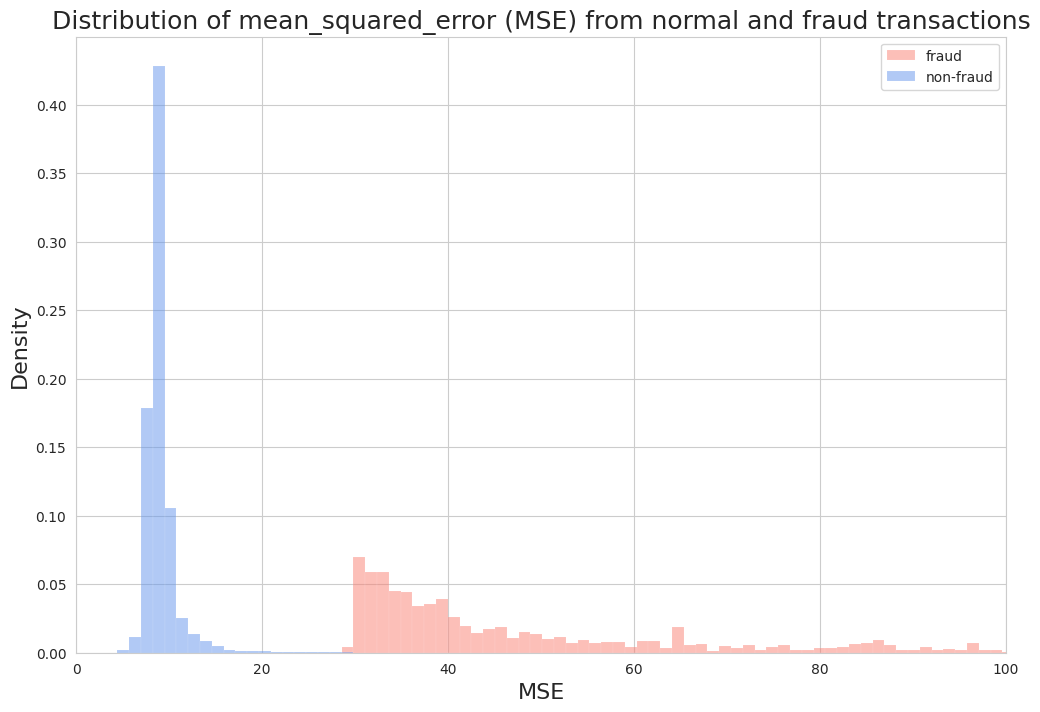

In [43]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df['label'] = df['is_anomaly'].apply(lambda x: 'fraud' if x == 1 else 'non-fraud')

# --- Generate the Plot ---
# Set the style and figure size
sns.set_style('whitegrid')
plt.figure(figsize=(12, 8))

# Create the histogram plot using seaborn
# `hue` separates the data based on the 'label' column
# `stat='density'` normalizes the histograms
# `common_norm=False` ensures each histogram is normalized independently
sns.histplot(
    data=df,
    x='mean_squared_error',
    hue='label',
    bins=1000,
    palette={'fraud': 'salmon', 'non-fraud': 'cornflowerblue'},
    stat='density',
    common_norm=False
)

# --- 3. Customize the Plot ---
# Set titles and labels with larger fonts
plt.title('Distribution of mean_squared_error (MSE) from normal and fraud transactions', fontsize=18)
plt.xlabel('MSE', fontsize=16)
plt.ylabel('Density', fontsize=16)

# Set the x-axis limit to match the example image
plt.xlim(0, 100)

# Customize the legend
plt.legend(title='', labels=['fraud', 'non-fraud'])

# Display the plot
plt.show()

pandas==2.3.1
numpy==1.26.4


In [27]:
%%bigquery df --project {PROJECT}
SELECT
    *
FROM
    ML.GENERATE_EMBEDDING(
    MODEL `anomaly_demo.autoencoder_model_emb3`,
  (  SELECT
     Amount, V1, V10, V11, V12, V13, V14, V15, V16, V17, V18, V19, V2, V20, V21, V22, V23, V24, V25, V26, V27, V28, V3, V4, V5, V6, V7, V8, V9, Class
  FROM `bigquery-public-data.ml_datasets.ulb_fraud_detection`)
    )

Query is running:   0%|          |

Downloading:   0%|          |

In [45]:
%%bigquery df --project {PROJECT}
SELECT
    *
FROM
    ML.PREDICT(
    MODEL `anomaly_demo.autoencoder_model_emb3`,
  (  SELECT
     Amount, V1, V10, V11, V12, V13, V14, V15, V16, V17, V18, V19, V2, V20, V21, V22, V23, V24, V25, V26, V27, V28, V3, V4, V5, V6, V7, V8, V9, Class
  FROM `bigquery-public-data.ml_datasets.ulb_fraud_detection`)
    )

Query is running:   0%|          |

Downloading:   0%|          |

In [46]:
df

,latent_col_1,latent_col_2,latent_col_3,Amount,V1,V10,V11,V12,V13,V14,...,V27,V28,V3,V4,V5,V6,V7,V8,V9,Class
0,0.650385,1.141247,3.331045,0.00,-1.070416,-0.310501,0.093971,-2.393761,1.597647,0.828945,...,-0.198600,0.098435,2.777064,2.154061,0.254450,-0.448529,-0.398691,0.144672,1.070900,0
1,0.000000,1.777139,4.442700,0.00,1.165628,0.517261,-0.995595,0.235335,0.000315,-0.212338,...,0.010182,0.019912,0.887635,2.740163,-0.338578,-0.142846,-0.055628,-0.015325,-0.213621,0
2,0.000000,2.090265,6.315452,0.00,1.050879,0.496674,0.341982,1.224831,0.264504,-0.605556,...,0.063834,0.010981,1.364590,2.666158,-0.378636,1.382032,-0.766202,0.486126,0.152611,0
3,0.000000,2.072280,4.922377,0.00,1.070316,0.340869,-1.141452,0.399501,-0.169194,-0.690727,...,0.065070,0.023500,1.471856,2.863786,-0.637887,0.858159,-0.687478,0.344146,0.459561,0
4,2.730376,5.159246,5.595892,0.00,-3.680953,0.635523,-0.442903,0.782333,0.218807,-0.412428,...,0.125419,0.243671,2.642743,4.263802,4.643286,-0.225053,-3.733637,1.273037,0.015661,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,0.524195,1.939043,3.345264,6.74,0.667714,-4.707571,4.905820,-5.208374,0.532498,-10.544011,...,0.821048,0.426175,-5.845112,5.967587,0.213863,-1.462923,-2.688761,0.677764,-3.447596,1
284803,1.845985,0.864822,2.068631,6.99,-2.405580,0.369936,0.382172,-2.262933,1.210605,-1.880619,...,-0.152502,-0.138866,-2.317843,1.367442,0.394001,1.919938,-3.106942,-10.764403,3.353525,1
284804,0.217986,1.584864,3.110580,18.96,0.333499,-2.834871,2.802005,-4.392732,-1.369671,-5.327287,...,0.551002,0.305473,-2.596561,3.643945,-0.585068,-0.654659,-2.275789,0.675229,-2.042416,1
284805,0.000000,2.400057,5.619061,18.96,-1.952933,-2.850324,2.024674,-6.487746,2.376463,-2.241516,...,0.532897,0.357892,-1.310561,5.955664,-1.003993,0.983049,-4.587235,-4.892184,-2.516752,1


In [18]:
# split_df = pd.DataFrame(df['ml_generate_embedding_result'].tolist(), index=df.index)
# split_df.columns = ['x_coordinate', 'y_coordinate', 'z_coordinate']
split_df['category'] = split_df['category']Class
split_df['point_size'] = 1
print(split_df)

        x_coordinate  y_coordinate  z_coordinate  embedding_3 category  \
0           0.675564      0.997761      2.428138     1.892079        1   
1           1.230457      0.603105      2.762848     2.350114        1   
2           1.093944      0.759839      3.046962     2.445634        1   
3           1.068125      0.912424      3.247009     2.684174        1   
4           0.000000      0.130670      1.509987     3.296653        1   
...              ...           ...           ...          ...      ...   
284802      2.085542      0.540780      7.475953     5.201477        1   
284803      1.870772      1.731125      3.889901     0.000000        1   
284804      1.562542      0.553670      5.195381     3.609266        1   
284805      2.097782      1.348755      8.498227     6.380358        1   
284806      0.821967      0.936397      4.310573     2.085160        1   

        point_size  
0                1  
1                1  
2                1  
3                1  
4     

In [ ]:
import pandas as pd
import plotly.express as px
import numpy as np

# 1. Create a sample pandas DataFrame
# Let's generate some random data for our example.
#np.random.seed(42) # for reproducibility
# data = {
#     'x_coordinate': np.random.rand(100) * 10,
#     'y_coordinate': np.random.rand(100) * 10,
#     'z_coordinate': np.random.rand(100) * 10,
#     'category': np.random.choice(['Group A', 'Group B', 'Group C'], 100),
#     'point_size': np.random.rand(100) * 50
# }
df = split_df #pd.DataFrame(data)

# Display the first 5 rows of the DataFrame
print("Sample DataFrame Head:")
print(df.head())

# 2. Create the interactive 3D scatter plot
# We map columns from the DataFrame to the x, y, and z axes.
# We can also map columns to color, size, and hover-text for more detail.
fig = px.scatter_3d(df, 
                    x='latent_col_1', 
                    y='latent_col_2', 
                    z='latent_col_3',
                    color='category',      # Color points based on the 'category' column
                    size='point_size',     # Set point size based on the 'point_size' column
                    opacity=0.7,           # Set marker opacity
                    title='Interactive 3D Scatter Plot of Sample Data',
                    labels={'x_coordinate': 'X Axis', 'y_coordinate': 'Y Axis', 'z_coordinate': 'Z Axis'}) # Custom axis labels

# Customize the layout for a cleaner look
fig.update_layout(margin=dict(l=0, r=0, b=0, t=40)) # Adjust plot margins

# 3. Display the plot in the Jupyter Notebook
fig.show()

Sample DataFrame Head:
   x_coordinate  y_coordinate  z_coordinate  embedding_3 category  point_size
0      0.675564      0.997761      2.428138     1.892079        1           1
1      1.230457      0.603105      2.762848     2.350114        1           1
2      1.093944      0.759839      3.046962     2.445634        1           1
3      1.068125      0.912424      3.247009     2.684174        1           1
4      0.000000      0.130670      1.509987     3.296653        1           1


### Predictions

In [ ]:
%%bigquery --project {PROJECT}
SELECT
  *
FROM
ML.DETECT_ANOMALIES(
  MODEL anomaly_demo.autoencoder_model,
  STRUCT(0.005 AS contamination),
  TABLE `bigquery-public-data.ml_datasets.ulb_fraud_detection`
)
WHERE is_anomaly=True
LIMIT 10;

In [26]:
ENDPOINT_ID = ''
print(ENDPOINT_ID)
from google.cloud import aiplatform as aiplatform
# Instantiate Vertex AI Endpoint object
endpoint_obj = aiplatform.Endpoint(ENDPOINT_ID)

ValueError: Resource  is not a valid resource id.

In [6]:
import json
ENDPOINT_ID = '7637712442369245184'
print(ENDPOINT_ID)
from google.cloud import aiplatform as aiplatform
# Instantiate Vertex AI Endpoint object
endpoint_obj = aiplatform.Endpoint(ENDPOINT_ID)

payload = {
  "scaled_Amount": 0.0,
  "scaled_V1": -0.356466189895633,
  "scaled_V10": -0.0599432188183031,
  "scaled_V11": -0.508270231790023,
  "scaled_V12": 0.425506043041155,
  "scaled_V13": 0.41430924445895395,
  "V14": -0.698375266726369,
  "V15": -1.46534865127239,
  "V16": -0.11900862525975699,
  "V17": -0.144735012716226,
  "V18": -1.33222124868776,
  "V19": -1.5474404930952599,
  "V2": 0.72541751522233922,
  "V20": -0.13360212033595698,
  "V21": 0.0208037896947035,
  "V22": 0.424311754701893,
  "V23": -0.015989128605843998,
  "V24": 0.466754445207633,
  "V25": -0.809962007197632,
  "V26": 0.65733441523423408,
  "V27": -0.0431501856619478,
  "V28": -0.0464013951451372,
  "V3": 1.97174888880699,
  "V4": 0.83134271510312285,
  "V5": 0.36968143455457897,
  "V6": -0.107776262637238,
  "V7": 0.75160990401556,
  "V8": -0.12016626006370801,
  "V9": -0.42067496794690296
}

print("-------------------------------------------------------")
print("[Payload to be sent to Vertex AI endpoint]")
print(json.dumps(payload,indent=4))
print("-------------------------------------------------------")

result = endpoint_obj.predict(instances = [payload])

print("-------------------------------------------------------")
print(f"[Prediction result]: {json.dumps(result, indent=4)}")
print("-------------------------------------------------------")

7637712442369245184
-------------------------------------------------------
[Payload to be sent to Vertex AI endpoint]
{
    "scaled_Amount": 0.0,
    "scaled_V1": -0.356466189895633,
    "scaled_V10": -0.0599432188183031,
    "scaled_V11": -0.508270231790023,
    "scaled_V12": 0.425506043041155,
    "scaled_V13": 0.41430924445895395,
    "V14": -0.698375266726369,
    "V15": -1.46534865127239,
    "V16": -0.11900862525975699,
    "V17": -0.144735012716226,
    "V18": -1.33222124868776,
    "V19": -1.5474404930952599,
    "V2": 0.7254175152223392,
    "V20": -0.13360212033595698,
    "V21": 0.0208037896947035,
    "V22": 0.424311754701893,
    "V23": -0.015989128605843998,
    "V24": 0.466754445207633,
    "V25": -0.809962007197632,
    "V26": 0.6573344152342341,
    "V27": -0.0431501856619478,
    "V28": -0.0464013951451372,
    "V3": 1.97174888880699,
    "V4": 0.8313427151031229,
    "V5": 0.36968143455457897,
    "V6": -0.107776262637238,
    "V7": 0.75160990401556,
    "V8": -0.12

Copyright 2019 Google Inc. Licensed under the Apache License, Version 2.0 (the "License"); you may not use this file except in compliance with the License. You may obtain a copy of the License at http://www.apache.org/licenses/LICENSE-2.0 Unless required by applicable law or agreed to in writing, software distributed under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. See the License for the specific language governing permissions and limitations under the License